<a href="https://colab.research.google.com/github/BrianAyekha/-connection-of-MySQL-database-to-NodeJs/blob/main/Week5_Supervised_Models.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 5 Assignment | Building Your First Supervised Machine Learning Model
**Project:** Early fault detection and diagnosis in hospital electromechanical equipment (infant warmer case study)

**Dataset:** AI4I 2020 Predictive Maintenance Dataset (UCI, id 601), used as a stand-in for infant warmer sensor data.

**Author:** Brian Ayekha Mwangala

## 1. Load the dataset

In [1]:
!pip install -q ucimlrepo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

# Download the dataset and join inputs (features) and targets into one table
ai4i = fetch_ucirepo(id=601)
df = pd.concat([ai4i.data.features, ai4i.data.targets], axis=1)
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (10000, 12)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Target and features

- **Target (output):** `Machine failure` (0 = normal, 1 = failure)
- **Features (inputs):** `Type`, `Air temperature`, `Process temperature`, `Rotational speed`, `Torque`, `Tool wear`

The failure-mode columns (`TWF`, `HDF`, `PWF`, `OSF`, `RNF`) are **not** used as features. They describe *why* a failure happened, so using them would leak the answer. `UID` and `Product ID` are only identifiers.

## 3. Regression or classification?

This is a **classification** problem. The target has only two categories (normal or failure), not a continuous number. The model must decide which class a machine belongs to, and it is not predicting a quantity such as a temperature. More precisely, it is **binary classification**.

In [2]:
# Define features (X) and target (y)
feature_cols = ["Type", "Air temperature", "Process temperature",
                "Rotational speed", "Torque", "Tool wear"]
X = df[feature_cols]
y = df["Machine failure"]

# Check the class balance
print(y.value_counts())
print(f"\nFailure rate: {y.mean() * 100:.2f}%")

Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure rate: 3.39%


## 4. Train/test split

I use 80% of the data for training and 20% for testing. Only about 3.4% of rows are failures, so I use `stratify=y`. This keeps the same failure rate in both sets, so the test set contains enough failures to evaluate on. `random_state=42` makes the split repeatable.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set:", X_train.shape, "| failures:", y_train.sum())
print("Test set    :", X_test.shape,  "| failures:", y_test.sum())

Training set: (8000, 6) | failures: 271
Test set    : (2000, 6) | failures: 68


## 5. Select and train two models

1. **Logistic Regression:** a simple, interpretable linear baseline. It estimates the probability of failure from a weighted sum of the features.
2. **Random Forest:** an ensemble of many decision trees. It can capture non-linear patterns and interactions between features (for example, high torque combined with high tool wear).

Both models use `class_weight="balanced"`, which gives the rare failure class more weight during training so the models do not simply predict "normal" every time.

**Preprocessing (same for both):** `Type` is categorical, so it is one-hot encoded. The numeric features are scaled. The preprocessing is placed in a pipeline so it is learned from the training data only.

In [4]:
numeric_cols = ["Air temperature", "Process temperature",
                "Rotational speed", "Torque", "Tool wear"]
categorical_cols = ["Type"]

# One-hot encode Type, scale numeric columns
preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(), categorical_cols),
])

# Model 1: Logistic Regression
log_reg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

# Model 2: Random Forest
rand_forest = Pipeline([
    ("prep", preprocess),
    ("model", RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                     random_state=42)),
])

# Train both models on the training data
log_reg.fit(X_train, y_train)
rand_forest.fit(X_train, y_train)
print("Both models trained.")

Both models trained.


## 6. Predictions on the test data

In [5]:
# Predicted classes (0 or 1)
pred_lr = log_reg.predict(X_test)
pred_rf = rand_forest.predict(X_test)

# Predicted probabilities of failure (needed for ROC AUC)
prob_lr = log_reg.predict_proba(X_test)[:, 1]
prob_rf = rand_forest.predict_proba(X_test)[:, 1]

# Show the first few predictions next to the true values
pd.DataFrame({
    "Actual": y_test.values[:10],
    "LogReg": pred_lr[:10],
    "RandomForest": pred_rf[:10],
})

,Actual,LogReg,RandomForest
0,0,1,0
1,0,1,0
2,0,1,0
3,0,0,0
4,0,1,0
5,0,1,0
6,0,1,0
7,0,0,0
8,0,0,0
9,0,1,0


## 7. Evaluation

Accuracy alone is misleading here. About 96.6% of the machines are normal, so a model that always predicts "normal" would score about 96.6% accuracy and detect no failures. I therefore also use:
- **Precision:** of the machines predicted to fail, how many really failed (false alarms lower it)
- **Recall:** of the machines that really failed, how many were caught (missed failures lower it)
- **F1-score:** the balance of precision and recall
- **ROC AUC:** how well the model ranks failures above normal cases across all thresholds
- **Confusion matrix:** the counts of correct and wrong predictions

I also include a "always predict normal" dummy model for reference only. It is not one of the two models.

In [6]:
def evaluate(name, y_true, y_pred, y_prob):
    return {
        "Model": name,
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall":    recall_score(y_true, y_pred),
        "F1":        f1_score(y_true, y_pred),
        "ROC AUC":   roc_auc_score(y_true, y_prob),
    }

# Reference: always predicts the majority class ("normal")
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)

results = pd.DataFrame([
    evaluate("Logistic Regression", y_test, pred_lr, prob_lr),
    evaluate("Random Forest",       y_test, pred_rf, prob_rf),
    {"Model": "Dummy (always normal)", "Accuracy": accuracy_score(y_test, pred_dummy),
     "Precision": 0.0, "Recall": 0.0, "F1": 0.0, "ROC AUC": 0.5},
]).set_index("Model")

results.round(3)

,Accuracy,Precision,Recall,F1,ROC AUC
Model,,,,,
Logistic Regression,0.824,0.142,0.824,0.242,0.907
Random Forest,0.979,0.906,0.426,0.580,0.964
Dummy (always normal),0.966,0.000,0.000,0.000,0.500


In [7]:
# Detailed report for each model
print("=== Logistic Regression ===")
print(classification_report(y_test, pred_lr, target_names=["Normal", "Failure"], zero_division=0))
print("=== Random Forest ===")
print(classification_report(y_test, pred_rf, target_names=["Normal", "Failure"], zero_division=0))

=== Logistic Regression ===
              precision    recall  f1-score   support

      Normal       0.99      0.82      0.90      1932
     Failure       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000

=== Random Forest ===
              precision    recall  f1-score   support

      Normal       0.98      1.00      0.99      1932
     Failure       0.91      0.43      0.58        68

    accuracy                           0.98      2000
   macro avg       0.94      0.71      0.78      2000
weighted avg       0.98      0.98      0.98      2000



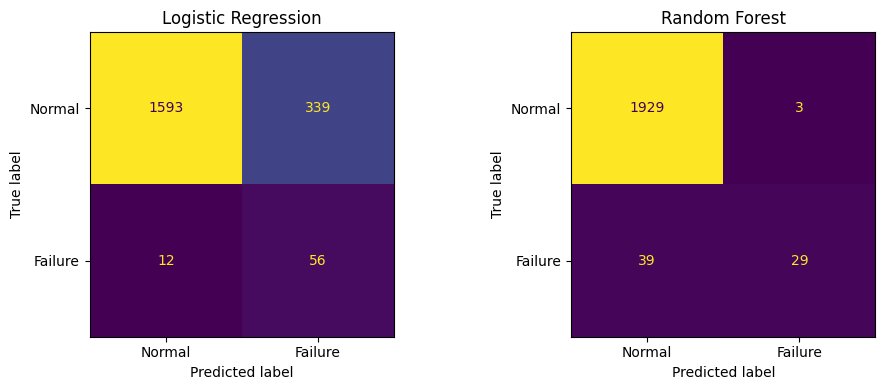

In [8]:
# Confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, [("Logistic Regression", pred_lr), ("Random Forest", pred_rf)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Normal", "Failure"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

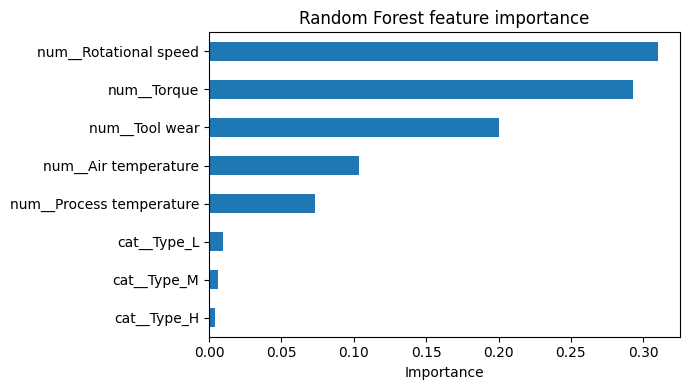

In [9]:
# Which features did the Random Forest rely on most?
rf_model = rand_forest.named_steps["model"]
feature_names = rand_forest.named_steps["prep"].get_feature_names_out()
importances = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values()

importances.plot(kind="barh", figsize=(7, 4), title="Random Forest feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 8. Comparison and discussion

In [10]:
# Automatic summary of the comparison, based on the actual results above
lr, rf = results.loc["Logistic Regression"], results.loc["Random Forest"]
for metric in ["Accuracy", "Precision", "Recall", "F1", "ROC AUC"]:
    better = "Random Forest" if rf[metric] > lr[metric] else "Logistic Regression"
    print(f"{metric:9s}: LogReg = {lr[metric]:.3f} | RF = {rf[metric]:.3f} -> higher: {better}")

tn, fp, fn, tp = confusion_matrix(y_test, pred_lr).ravel()
print(f"\nLogReg: caught {tp} of {tp+fn} failures, {fp} false alarms")
tn, fp, fn, tp = confusion_matrix(y_test, pred_rf).ravel()
print(f"RF    : caught {tp} of {tp+fn} failures, {fp} false alarms")

Accuracy : LogReg = 0.825 | RF = 0.979 -> higher: Random Forest
Precision: LogReg = 0.142 | RF = 0.906 -> higher: Random Forest
Recall   : LogReg = 0.824 | RF = 0.426 -> higher: Logistic Regression
F1       : LogReg = 0.242 | RF = 0.580 -> higher: Random Forest
ROC AUC  : LogReg = 0.907 | RF = 0.964 -> higher: Random Forest

LogReg: caught 56 of 68 failures, 339 false alarms
RF    : caught 29 of 68 failures, 3 false alarms


**Discussion**

Read this together with the results table and the summary printed above.

- **Accuracy is not enough.** Both models, and even the dummy model, can show high accuracy because failures are rare. Precision, recall and F1 on the *failure* class are the metrics that matter.
- **Typical pattern.** Logistic Regression with balanced weights usually catches many failures (high recall) but raises many false alarms (low precision), because a straight-line boundary cannot describe failures that depend on combinations of features. Random Forest can model these non-linear patterns, so it usually gives higher precision, F1 and ROC AUC. The feature importance plot shows which sensor readings it relied on. I need to confirm in my own table which model actually performed better.
- **Which matters more?** For an infant warmer, a missed failure (false negative) is more dangerous than a false alarm (false positive), so recall carries a lot of weight. Too many false alarms would still make technicians ignore the system, so precision cannot be ignored.
- **Limitations.**
  - The data is synthetic and comes from a milling machine, not from infant warmers.
  - I used a single train/test split and no hyperparameter tuning, so the numbers could change with a different split.
  - The test set contains only a small number of failures, which makes recall and precision noisy.
- **Next steps.** Try cross-validation, tune the models, adjust the decision threshold to favour recall, add an engineered feature such as the difference between process and air temperature, and test on real logged data from my warmer prototype.